# Who to Reward, Who to Win Back: RFM Segmentation of 17,415 E-Commerce Customers

**Author:** Pham Hong Hieu (Haven) · **Data:** 51,290 order lines from a beauty and home-care e-commerce retailer,
2020–2023 (synthetic, educational)

## The question

The CRM team sends the same campaigns to every customer. They want to know which customers to reward, which to
develop and which to win back before they are lost. RFM scores each customer on three behaviours:

- **Recency (R):** days since the last purchase. More recent is better.
- **Frequency (F):** number of distinct orders.
- **Monetary (M):** total net revenue.

The scores map to named segments, and the notebook measures how many customers and how much revenue each segment
holds.

## 1. Setup and data loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "figure.dpi": 110})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
TABLE_DIR = Path("../reports/tables")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
sales = pd.read_csv(DATA_DIR / "EcomSales.csv", parse_dates=["OrderDate"], date_format="%m/%d/%Y")
print(f"{len(sales):,} order lines, {sales['OrderID'].nunique():,} orders, {sales['CustomerID'].nunique():,} customers")
print("Period:", sales["OrderDate"].min().date(), "to", sales["OrderDate"].max().date())
print("Duplicate lines:", sales.duplicated().sum(), "| Missing CustomerID:", sales["CustomerID"].isna().sum())

51,290 order lines, 25,728 orders, 17,415 customers
Period: 2020-01-01 to 2023-12-31
Duplicate lines: 0 | Missing CustomerID: 0


## 2. Net revenue per order line

`Sales` is treated as gross line revenue before discount, so net revenue is `Sales × (1 − Discount)`. Monetary
value is based on net revenue, which is what the customer actually paid.

In [3]:
sales["Revenue"] = sales["Sales"] * (1 - sales["Discount"])
sales[["OrderID", "CustomerID", "OrderDate", "Sales", "Discount", "Revenue"]].head()

,OrderID,CustomerID,OrderDate,Sales,Discount,Revenue
0,IN-2012-TH211151-41003,TH-211151,2020-04-04,416,0.00,416.00
1,ID-2013-BD116051-41518,BD-116051,2021-09-01,20,0.00,20.00
2,IN-2015-TS212051-42173,TS-212051,2023-06-18,20,0.00,20.00
3,IN-2014-SU206651-41899,SU-206651,2022-09-17,556,0.00,556.00
4,IN-2015-GM144551-42217,GM-144551,2023-08-01,6,0.00,6.00


## 3. RFM metrics

The analysis date is **one day after the last transaction** (2024-01-01) rather than today's date, so the results
are reproducible.

In [4]:
snapshot = sales["OrderDate"].max() + pd.Timedelta(days=1)
rfm = sales.groupby("CustomerID").agg(
    last_order=("OrderDate", "max"),
    frequency=("OrderID", "nunique"),
    monetary=("Revenue", "sum"),
)
rfm["recency"] = (snapshot - rfm["last_order"]).dt.days
rfm = rfm.reset_index()
print("Snapshot date:", snapshot.date())
rfm.describe()[["recency", "frequency", "monetary"]]

Snapshot date: 2024-01-01


,recency,frequency,monetary
count,"17,415.00","17,415.00","17,415.00"
mean,508.09,1.48,319.56
min,1.00,1.00,0.80
25%,149.00,1.00,50.00
50%,422.00,1.00,140.00
75%,804.00,2.00,366.27
max,"1,461.00",9.00,"6,840.00"
std,400.62,0.85,515.72


## 4. Scoring

- **R and M** are split into quintiles. Low recency scores 5 and high monetary value scores 5.
- **F** has only nine distinct values and heavy ties: most customers placed one or two orders. Quintiles of
  customers would put identical customers into different scores, so the five bins are built on the *distinct*
  frequency values. Customers with the same number of orders always get the same F score.

In [5]:
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

freq_bins = pd.DataFrame({"frequency": np.sort(rfm["frequency"].unique())})
freq_bins["F"] = pd.qcut(freq_bins["frequency"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm = rfm.merge(freq_bins, on="frequency", how="left")
rfm["RFM"] = rfm["R"] * 100 + rfm["F"] * 10 + rfm["M"]

display(freq_bins.groupby("F")["frequency"].agg(["min", "max"]).rename(columns={"min": "orders_from", "max": "orders_to"}))

,orders_from,orders_to
F,,
1,1,2
2,3,4
3,5,5
4,6,7
5,8,9


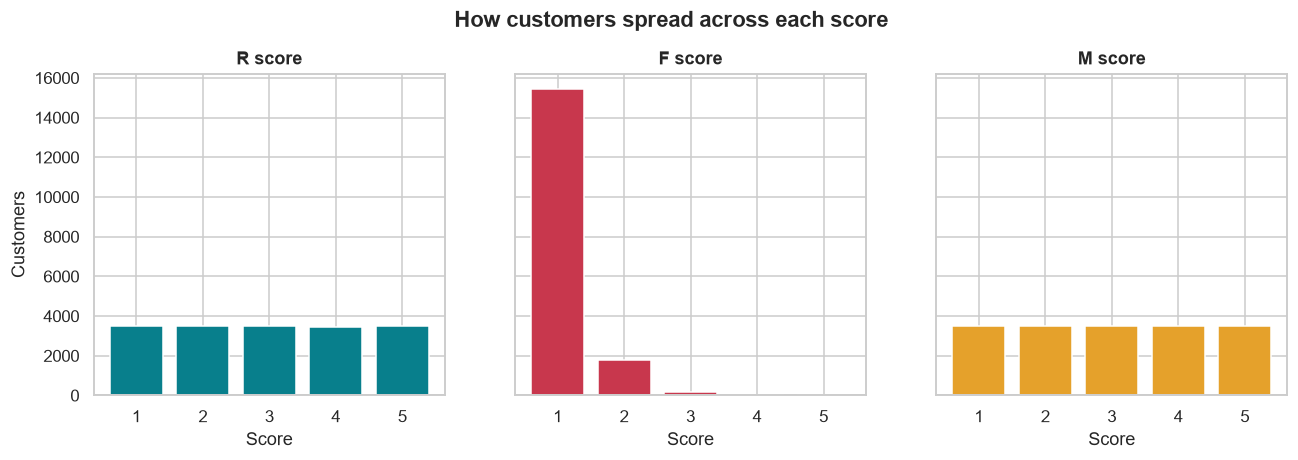

Customers with F = 1 (one or two orders): 88.7%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, score, colour in zip(axes, ["R", "F", "M"], ["#087F8C", "#C8374D", "#E5A12B"]):
    counts = rfm[score].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=colour)
    ax.set(title=f"{score} score", xlabel="Score", ylabel="Customers" if score == "R" else "")
    ax.set_xticks(range(1, 6))
fig.suptitle("How customers spread across each score", fontweight="bold", y=1.03)
save(fig, "01_score_distribution")
plt.show()
print(f"Customers with F = 1 (one or two orders): {(rfm['F'] == 1).mean():.1%}")

R and M are evenly spread by design. **F is not.** Nearly nine customers in ten have an F score of 1, because
most customers bought only once or twice over four years. Repeat purchasing is rare in this business, and the segments
below are therefore shaped mainly by recency and spend.

## 5. Segments

Score combinations are mapped to eleven segments, following a widely used RFM segment grid.

In [7]:
SEGMENTS = {
    "Champions": [555, 554, 544, 545, 454, 455, 445],
    "Loyal": [543, 444, 435, 355, 354, 345, 344, 335],
    "Potential Loyalist": [553, 551, 552, 541, 542, 533, 532, 531, 452, 451, 442, 441, 431, 453, 433, 432, 423,
                           353, 352, 351, 342, 341, 333, 323],
    "Promising": [525, 524, 523, 522, 521, 515, 514, 513, 425, 424, 413, 414, 415, 315, 314, 313],
    "New Customers": [512, 511, 422, 421, 412, 411, 311],
    "Need Attention": [535, 534, 443, 434, 343, 334, 325, 324],
    "About to Sleep": [331, 321, 312, 221, 213, 231, 241, 251],
    "At Risk": [255, 254, 245, 244, 253, 252, 243, 242, 235, 234, 225, 224, 153, 152, 145, 143, 142, 135, 134,
                133, 125, 124],
    "Cannot Lose Them": [155, 154, 144, 214, 215, 115, 114, 113],
    "Hibernating": [332, 322, 233, 232, 223, 222, 132, 123, 122, 212, 211],
    "Lost": [111, 112, 121, 131, 141, 151],
}
lookup = {code: name for name, codes in SEGMENTS.items() for code in codes}
rfm["segment"] = rfm["RFM"].map(lookup).fillna("Other")
print("Customers not covered by the grid:", (rfm["segment"] == "Other").sum())

summary = (rfm.groupby("segment")
           .agg(customers=("CustomerID", "count"), revenue=("monetary", "sum"),
                avg_recency=("recency", "mean"), avg_frequency=("frequency", "mean"),
                revenue_per_customer=("monetary", "mean"))
           .sort_values("revenue", ascending=False))
summary["customer_pct"] = summary["customers"] / summary["customers"].sum() * 100
summary["revenue_pct"] = summary["revenue"] / summary["revenue"].sum() * 100
summary.to_csv(TABLE_DIR / "segment_summary.csv")

# Customer-level scores so the CRM team can build campaign audiences directly
(rfm[["CustomerID", "last_order", "recency", "frequency", "monetary", "R", "F", "M", "RFM", "segment"]]
 .sort_values(["segment", "monetary"], ascending=[True, False])
 .to_csv(TABLE_DIR / "customer_rfm_scores.csv", index=False))
summary

Customers not covered by the grid: 0


,customers,revenue,avg_recency,avg_frequency,revenue_per_customer,customer_pct,revenue_pct
segment,,,,,,,
Promising,6169,"3,087,237.39",212.63,1.77,500.44,35.42,55.48
Cannot Lose Them,2820,"1,392,094.89",979.16,1.19,493.65,16.19,25.01
Need Attention,385,"387,676.88",327.06,3.67,"1,006.95",2.21,6.97
About to Sleep,1370,"142,877.23",573.11,1.19,104.29,7.87,2.57
At Risk,158,"120,780.49",729.38,3.30,764.43,0.91,2.17
New Customers,2988,"112,853.34",194.03,1.13,37.77,17.16,2.03
Loyal,62,"104,210.27",274.89,5.11,"1,680.81",0.36,1.87
Lost,1720,"70,677.76","1,150.51",1.03,41.09,9.88,1.27
Hibernating,1583,"69,107.34",716.61,1.14,43.66,9.09,1.24


## 6. Segment size versus revenue

The two treemaps compare each segment's share of customers with its share of revenue.

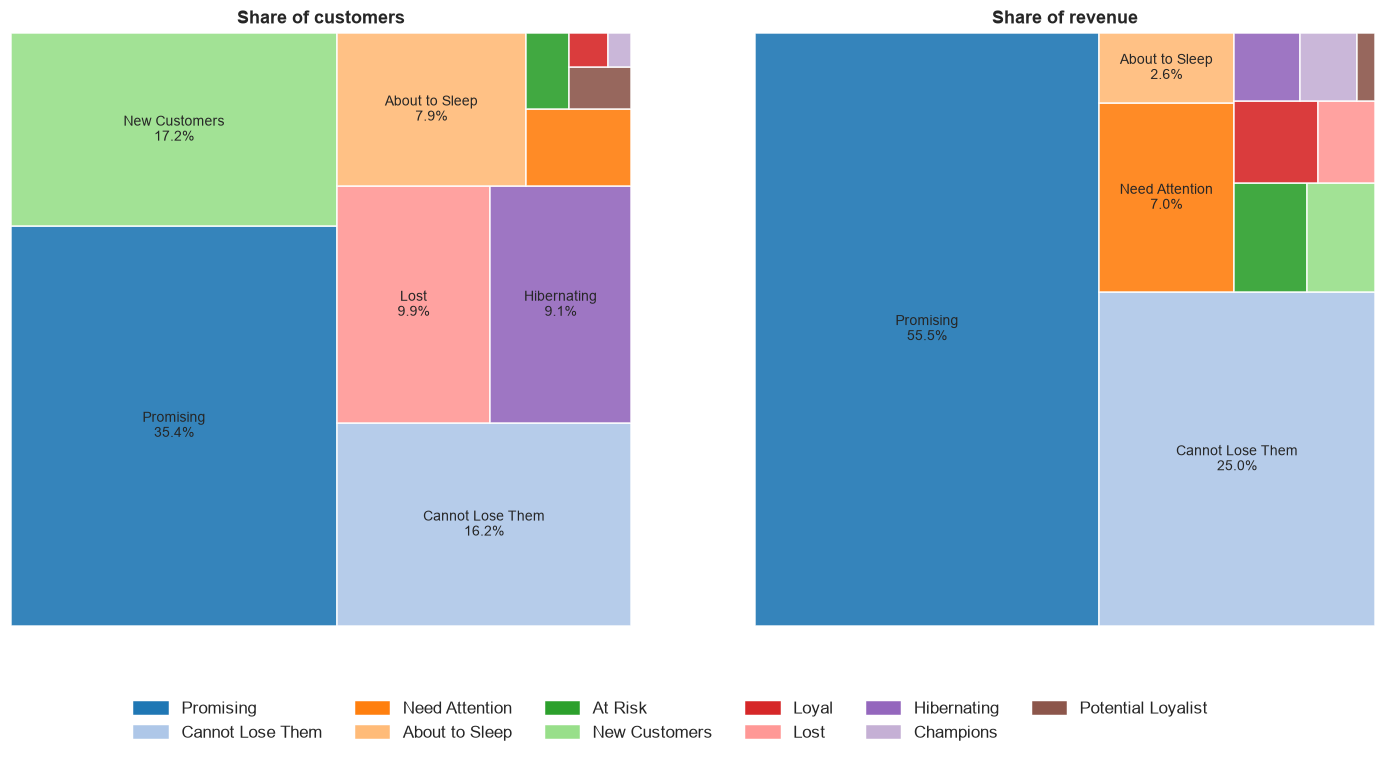

In [8]:
palette = dict(zip(summary.index, sns.color_palette("tab20", len(summary))))
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, column, title in [(axes[0], "customers", "Share of customers"), (axes[1], "revenue", "Share of revenue")]:
    data = summary[summary[column] > 0].sort_values(column, ascending=False)
    pct = data[column] / data[column].sum() * 100
    labels = [f"{name}\n{p:.1f}%" if p >= 2.5 else "" for name, p in zip(data.index, pct)]
    squarify.plot(sizes=data[column], label=labels, color=[palette[s] for s in data.index],
                  alpha=0.9, text_kwargs={"fontsize": 9}, ax=ax, pad=False)
    ax.set_title(title)
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[s]) for s in summary.index]
fig.legend(handles, summary.index, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.06))
save(fig, "02_segment_treemaps")
plt.show()

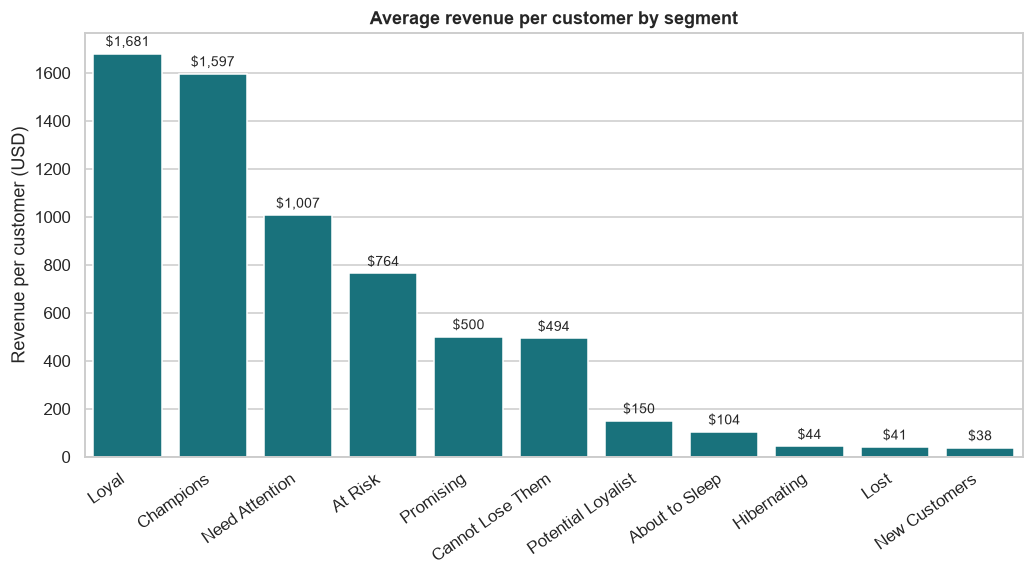

In [9]:
per_customer = summary.sort_values("revenue_per_customer", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=per_customer.index, y=per_customer["revenue_per_customer"], color="#087F8C", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="${:,.0f}", padding=3, fontsize=9)
ax.set(title="Average revenue per customer by segment", xlabel="", ylabel="Revenue per customer (USD)")
ax.tick_params(axis="x", rotation=35)
for label in ax.get_xticklabels():
    label.set_ha("right")
save(fig, "03_revenue_per_customer")
plt.show()

## 7. Key findings

In [10]:
def seg(name, field):
    return summary.loc[name, field] if name in summary.index else 0.0

top_two = summary.head(2)
print(f"Top two segments by revenue: {', '.join(top_two.index)}")
print(f"  {top_two['customer_pct'].sum():.1f}% of customers, {top_two['revenue_pct'].sum():.1f}% of revenue")
for name in ["Promising", "Cannot Lose Them", "Need Attention", "Champions", "Loyal"]:
    print(f"{name:<17} customers {seg(name, 'customer_pct'):5.1f}% | revenue {seg(name, 'revenue_pct'):5.1f}% | "
          f"${seg(name, 'revenue_per_customer'):,.0f} per customer | avg recency {seg(name, 'avg_recency'):,.0f} days")

Top two segments by revenue: Promising, Cannot Lose Them
  51.6% of customers, 80.5% of revenue
Promising         customers  35.4% | revenue  55.5% | $500 per customer | avg recency 213 days
Cannot Lose Them  customers  16.2% | revenue  25.0% | $494 per customer | avg recency 979 days
Need Attention    customers   2.2% | revenue   7.0% | $1,007 per customer | avg recency 327 days
Champions         customers   0.2% | revenue   1.1% | $1,597 per customer | avg recency 90 days
Loyal             customers   0.4% | revenue   1.9% | $1,681 per customer | avg recency 275 days


1. **Revenue sits in two segments.** *Promising* and *Cannot Lose Them* hold about half of all customers and about
   80% of revenue.
2. **Promising is the growth engine.** These customers bought recently and spent well (high R and M) but only once
   or twice. A second and third order is the main growth lever.
3. **Cannot Lose Them is the main retention risk.** These are high spenders whose last order was more than two and a
   half years ago, on average. Many of them bought only once, so a win-back campaign is a bet on reactivating a single
   large order, and it should be tested on a sample before rolling out.
4. **Champions and Loyal customers are rare but the most valuable per head.** Together they are under 1% of customers,
   with roughly three times the revenue per customer of Promising.
5. **Need Attention is small but valuable.** It has about 2% of customers, roughly 7% of revenue, and more than twice
   the revenue per customer of Promising.

## 8. Recommended actions

| Segment | Objective | Actions |
|---|---|---|
| Champions, Loyal | Retain and reward | VIP tier, early access, referral programme |
| Potential Loyalist, Promising | Earn the next order | Personalised bundles, second-purchase incentive, loyalty enrolment |
| New Customers | Second purchase | Welcome series and onboarding offer |
| Need Attention | Stop the slide | Personal reminders and targeted offers |
| About to Sleep | Re-engage early | Time-limited offers |
| At Risk, Cannot Lose Them | Win back | Tested win-back offers, personal outreach for the highest spenders |
| Hibernating, Lost | Contain cost | Low-cost automated campaigns only |

## 9. Limitations

- The data are synthetic and educational.
- Low repeat purchasing compresses the F score, so the segment grid behaves mostly as an R×M grid. A business with
  more repeat buying would see a more even spread of segments.
- RFM describes past behaviour. It does not predict response to a campaign, so offers should be validated with
  control groups.